In [8]:
import sqlite3
import pandas as pd

con = sqlite3.connect("store.db")

df_orders = pd.read_csv("store_orders.csv")
df_customers = pd.read_csv("store_customers.csv")

df_orders.to_sql("orders", con, index=False, if_exists="replace")
df_customers.to_sql("customers", con, index=False, if_exists="replace")

print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", con))

        name
0     orders
1  customers


In [9]:

print("--- First 5 Rows of Orders ---")
print(pd.read_sql("SELECT * FROM orders LIMIT 5;", con))

query_filtered = """
    SELECT * FROM orders 
    WHERE amount > 100 
    ORDER BY amount DESC;
"""
print("\n--- Orders Over $100 (Sorted Descending) ---")
print(pd.read_sql(query_filtered, con))

--- First 5 Rows of Orders ---
   order_id  customer_id  product     category  amount  order_date
0      5000            4    paper       office   14.09  2026-05-25
1      5001           15  planner       office   51.86  2026-05-08
2      5002           34    shelf    furniture  116.25  2026-06-03
3      5003            2  granola       snacks   19.72  2026-05-19
4      5004           17  monitor  electronics  284.80  2026-05-10

--- Orders Over $100 (Sorted Descending) ---
    order_id  customer_id  product     category  amount  order_date
0       5153           20     dock  electronics  499.00  2026-05-25
1       5140           30  headset  electronics  295.36  2026-05-26
2       5047          901  headset  electronics  293.79  2026-05-15
3       5150          903  monitor  electronics  293.35  2026-06-06
4       5014            6  monitor  electronics  287.83  2026-05-22
..       ...          ...      ...          ...     ...         ...
79      5107           38    shelf    furnitu

In [10]:

query_category = """
    SELECT category, 
           COUNT(*) AS n, 
           AVG(amount) AS avg_amount
    FROM orders
    GROUP BY category
    ORDER BY avg_amount DESC;
"""
print("--- Step 4: Category Aggregates ---")
print(pd.read_sql(query_category, con))


query_city_spend = """
    SELECT c.city, 
           SUM(o.amount) AS total_spend
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    GROUP BY c.city
    ORDER BY total_spend DESC;
"""
print("\n--- Step 5: Total Spend by Customer City ---")
df_city_spend = pd.read_sql(query_city_spend, con)
print(df_city_spend)

--- Step 4: Category Aggregates ---
      category   n  avg_amount
0  electronics  60  190.569500
1    furniture  46  146.251522
2       office  51   30.132549
3       snacks  43   14.619767

--- Step 5: Total Spend by Customer City ---
           city  total_spend
0   Los Angeles      5862.99
1   Culver City      5316.88
2  Santa Monica      4017.93
3     Inglewood      2718.25
4      Torrance      1037.25
5        Venice       462.36


Step 6: Row-Count Audit
The original `orders` table contains 200 rows, while the inner join between `orders` and `customers` produces 195 rows. These differ because 5 orders belong to customer IDs that do not exist in the `customers` table, causing them to drop out of the inner join.

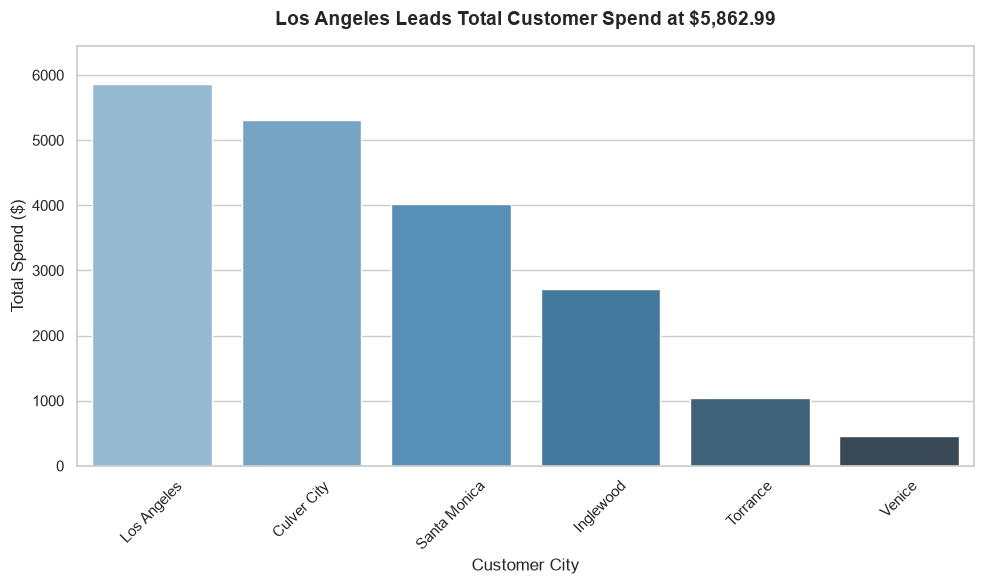

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_city_spend, x="city", y="total_spend", hue="city", palette="Blues_d", legend=False
)

plt.title("Los Angeles Leads Total Customer Spend at $5,862.99", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Customer City", fontsize=12)
plt.ylabel("Total Spend ($)", fontsize=12)

plt.ylim(0, df_city_spend["total_spend"].max() * 1.1)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 8: Custom Business Inquiry
Question: Which product category generates the highest total revenue?

In [12]:
query_custom = """
    SELECT category, SUM(amount) AS total_revenue
    FROM orders
    GROUP BY category
    ORDER BY total_revenue DESC;
"""
print(pd.read_sql(query_custom, con))

      category  total_revenue
0  electronics       11434.17
1    furniture        6727.57
2       office        1536.76
3       snacks         628.65


Finding: The electronics category generates the highest total revenue by a significant margin compared to snacks, office supplies, and furniture.

Step 9: Ethics Note & Safe Push
Before sharing analytics results publicly or pushing code to GitHub, PII such as customer names, exact street addresses, and raw customer contact info should be stripped or aggregated (e.g., analyzed only at the city level) to protect individual privacy. Furthermore, local database files like store.db and raw CSV data must be kept out of public repositories by adding them to your .gitignore file.